# Burgers PINN — development notebook

Exploration only. Load-bearing code lives in `src/` (per project convention).

**Step 2:** validate the Cole–Hopf reference solution (ground truth for relative-L2 scoring).

PDE: $u_t + u\,u_x = \nu\,u_{xx}$, $\nu=0.01/\pi$, $x\in[-1,1]$, $t\in[0,1]$,
IC $u(x,0)=-\sin(\pi x)$, BC $u(\pm 1,t)=0$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))  # make src importable from notebooks/

import numpy as np
import matplotlib.pyplot as plt

from src.pdes.burgers import (
    cole_hopf_reference, initial_condition, reference_field, NU_DEFAULT,
)
print(f'nu = {NU_DEFAULT:.6e}')

nu = 3.183099e-03


## Validate the reference before trusting it

In [2]:
x = np.linspace(-1, 1, 401)

# IC must be reproduced exactly at t=0
ic_err = np.max(np.abs(cole_hopf_reference(x, np.zeros_like(x)) - initial_condition(x)))

# BC ~ 0 at x = +-1 for all t
t = np.linspace(0, 1, 50)
bc_err = max(np.max(np.abs(cole_hopf_reference(np.full_like(t, s), t))) for s in (-1.0, 1.0))

# odd symmetry: u(-x,t) = -u(x,t)
xr = np.linspace(0, 1, 200); tt = np.full_like(xr, 0.5)
sym_err = np.max(np.abs(cole_hopf_reference(-xr, tt) + cole_hopf_reference(xr, tt)))

print(f'IC error       : {ic_err:.2e}   (expect 0)')
print(f'BC error       : {bc_err:.2e}   (expect ~1e-16)')
print(f'odd-symmetry   : {sym_err:.2e}   (expect ~1e-16)')
assert ic_err < 1e-12 and bc_err < 1e-10 and sym_err < 1e-10, 'reference failed validation'
print('reference validated ✓')

IC error       : 0.00e+00   (expect 0)
BC error       : 8.48e-16   (expect ~1e-16)
odd-symmetry   : 4.44e-16   (expect ~1e-16)
reference validated ✓


## Visualize: heatmap + snapshots (shock sharpens at x=0)

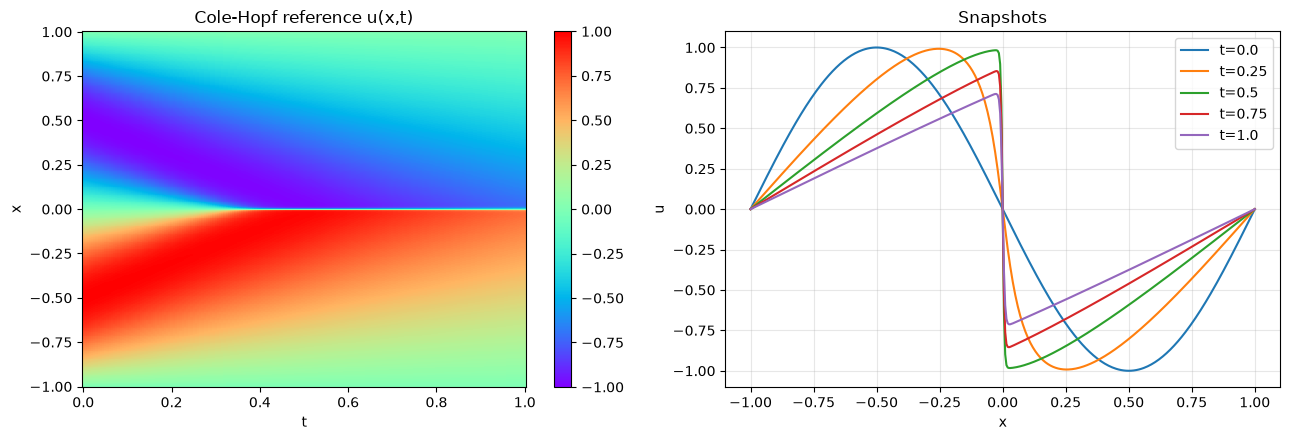

In [3]:
x, t, U = reference_field(nx=401, nt=201)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
pc = ax1.pcolormesh(t, x, U.T, cmap='rainbow', shading='auto')
ax1.set_xlabel('t'); ax1.set_ylabel('x'); ax1.set_title('Cole-Hopf reference u(x,t)')
fig.colorbar(pc, ax=ax1)
for tq in [0.0, 0.25, 0.5, 0.75, 1.0]:
    ax2.plot(x, cole_hopf_reference(x, np.full_like(x, tq)), label=f't={tq}')
ax2.set_xlabel('x'); ax2.set_ylabel('u'); ax2.set_title('Snapshots')
ax2.legend(); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()